# Taller 02 - Ciencia de Datos

## Aprendizaje de Máquina para el Análisis del Rendimiento de Ventas en Comercio Electrónico

**Maestría en Ciencia de Datos**

Este proyecto utiliza el conjunto de datos **Online Retail II** para analizar el comportamiento de compra de los clientes y aplicar técnicas de aprendizaje automático.

El desarrollo incluye:

- Preparación y limpieza de datos.
- Análisis exploratorio.
- Clasificación de clientes.
- Segmentación mediante K-Means y Mean Shift.
- Predicción de ventas.

# Parte 0 - Preparación de los datos

En esta sección se realizará la carga, exploración y limpieza inicial del conjunto de datos.

Se revisarán:

- Dimensiones del dataset.
- Tipos de variables.
- Valores faltantes.
- Registros duplicados.
- Pedidos cancelados.
- Transacciones sin identificación del cliente.

## 0.1 Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## 0.2 Carga completa del conjunto de datos

El archivo Online Retail II contiene dos hojas correspondientes a los períodos 2009-2010 y 2010-2011.

Para realizar el análisis completo, se cargan ambas hojas y se integran en un único conjunto de datos.

In [2]:
df_2009_2010 = pd.read_excel(
    "online_retail_II.xlsx",
    sheet_name="Year 2009-2010"
)

df_2010_2011 = pd.read_excel(
    "online_retail_II.xlsx",
    sheet_name="Year 2010-2011"
)

df = pd.concat(
    [df_2009_2010, df_2010_2011],
    ignore_index=True
)

print("Dataset completo cargado correctamente")
print("Dimensiones del dataset:", df.shape)

Dataset completo cargado correctamente
Dimensiones del dataset: (1067371, 8)


## 0.3 Exploración inicial del dataset

Antes de realizar la limpieza, se revisa la estructura general del conjunto de datos, incluyendo sus dimensiones, columnas, tipos de variables y primeros registros.

In [3]:
print("Dimensiones del dataset:")
print(df.shape)

Dimensiones del dataset:
(1067371, 8)


In [4]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.tail()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


## 0.4 Análisis de valores faltantes

Se identifican los valores faltantes presentes en cada variable del conjunto de datos.

Este análisis permite determinar qué columnas requieren tratamiento antes de continuar con el análisis exploratorio y la aplicación de modelos de aprendizaje automático.

In [7]:
valores_nulos = df.isnull().sum()

valores_nulos

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [8]:
porcentaje_nulos = (df.isnull().sum() / len(df)) * 100

resumen_nulos = pd.DataFrame({
    "Valores faltantes": df.isnull().sum(),
    "Porcentaje (%)": porcentaje_nulos.round(2)
})

resumen_nulos

,Valores faltantes,Porcentaje (%)
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


## 0.5 Análisis de registros duplicados

Se identifican registros duplicados dentro del conjunto de datos, ya que estos pueden generar distorsiones en los análisis de ventas, frecuencia de compra y comportamiento de los clientes.

In [9]:
duplicados = df.duplicated().sum()

print("Cantidad de registros duplicados:", duplicados)

Cantidad de registros duplicados: 34335


In [10]:
porcentaje_duplicados = (duplicados / len(df)) * 100

print(f"Porcentaje de registros duplicados: {porcentaje_duplicados:.2f}%")

Porcentaje de registros duplicados: 3.22%


## 0.6 Análisis de pedidos cancelados

Se identifican los pedidos cancelados mediante el número de factura.

En el conjunto de datos, las facturas que comienzan con la letra **C** corresponden a transacciones canceladas. Estas operaciones deben identificarse antes de realizar el análisis de ventas.

In [11]:
cancelados = df["Invoice"].astype(str).str.startswith("C").sum()

print("Cantidad de pedidos cancelados:", cancelados)

Cantidad de pedidos cancelados: 19494


In [12]:
porcentaje_cancelados = (cancelados / len(df)) * 100

print(f"Porcentaje de pedidos cancelados: {porcentaje_cancelados:.2f}%")

Porcentaje de pedidos cancelados: 1.83%


## 0.7 Transacciones sin identificación del cliente

Se identifican las transacciones que no contienen un valor en la variable **Customer ID**.

Estas transacciones no pueden asociarse a un cliente específico, por lo que no serán útiles para los análisis posteriores de clasificación y segmentación de clientes.

In [13]:
sin_customer_id = df["Customer ID"].isnull().sum()

print("Transacciones sin Customer ID:", sin_customer_id)

Transacciones sin Customer ID: 243007


In [14]:
porcentaje_sin_customer = (sin_customer_id / len(df)) * 100

print(f"Porcentaje de transacciones sin Customer ID: {porcentaje_sin_customer:.2f}%")

Porcentaje de transacciones sin Customer ID: 22.77%


## 0.8 Limpieza del dataset

Una vez identificados los principales problemas de calidad de los datos, se procede a limpiar el conjunto de datos.

Las acciones realizadas son:

- Eliminación de registros duplicados.
- Eliminación de pedidos cancelados.
- Eliminación de transacciones sin identificación del cliente.
- Eliminación de registros sin descripción del producto.

In [15]:
df_limpio = df.copy()

print("Registros antes de la limpieza:", len(df_limpio))

Registros antes de la limpieza: 1067371


In [16]:
df_limpio = df_limpio.drop_duplicates()

print("Registros después de eliminar duplicados:", len(df_limpio))

Registros después de eliminar duplicados: 1033036


In [17]:
df_limpio = df_limpio[
    ~df_limpio["Invoice"].astype(str).str.startswith("C")
]

print("Registros después de eliminar pedidos cancelados:", len(df_limpio))

Registros después de eliminar pedidos cancelados: 1013932


In [18]:
df_limpio = df_limpio.dropna(subset=["Customer ID"])

print("Registros después de eliminar Customer ID faltantes:", len(df_limpio))

Registros después de eliminar Customer ID faltantes: 779495


In [19]:
df_limpio = df_limpio.dropna(subset=["Description"])

print("Registros finales después de la limpieza:", len(df_limpio))

Registros finales después de la limpieza: 779495


### 0.8.1 Validación de la limpieza

Se verifica que el conjunto de datos resultante no contenga valores faltantes relevantes, registros duplicados ni pedidos cancelados.

In [20]:
df_limpio.isnull().sum()

Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64

In [21]:
print("Duplicados restantes:", df_limpio.duplicated().sum())

print(
    "Pedidos cancelados restantes:",
    df_limpio["Invoice"].astype(str).str.startswith("C").sum()
)

Duplicados restantes: 0
Pedidos cancelados restantes: 0


In [22]:
print("Dimensiones finales del dataset limpio:", df_limpio.shape)

Dimensiones finales del dataset limpio: (779495, 8)


## 0.9 Análisis exploratorio de datos

Una vez finalizada la limpieza, se realiza un análisis exploratorio para comprender el comportamiento general de las ventas.

Se analizarán:

- Cantidad de productos comprados.
- Precio de los productos.
- Valor total de las ventas.
- Productos más vendidos.
- Productos con mayores ingresos.
- Evolución de las ventas en el tiempo.
- Patrones estacionales.

In [23]:
df_limpio["TotalVenta"] = (
    df_limpio["Quantity"] * df_limpio["Price"]
)

df_limpio.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalVenta
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


### 0.9.1 Estadísticas descriptivas

In [24]:
df_limpio[
    ["Quantity", "Price", "TotalVenta"]
].describe()

,Quantity,Price,TotalVenta
count,779495.000000,779495.000000,779495.000000
mean,13.507085,3.218199,22.289821
std,146.540284,29.674823,227.416962
min,1.000000,0.000000,0.000000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,12.480000
75%,12.000000,3.750000,19.800000
max,80995.000000,10953.500000,168469.600000


### 0.9.2 Revisión de registros con precio igual a cero

Se identifican transacciones cuyo precio unitario es igual a cero, ya que estas no representan una venta efectiva y podrían afectar el análisis de ingresos y los modelos posteriores.

In [25]:
precio_cero = (df_limpio["Price"] == 0).sum()

print("Registros con Price igual a 0:", precio_cero)

Registros con Price igual a 0: 70


In [26]:
porcentaje_precio_cero = (precio_cero / len(df_limpio)) * 100

print(f"Porcentaje de registros con Price igual a 0: {porcentaje_precio_cero:.2f}%")

Porcentaje de registros con Price igual a 0: 0.01%


In [27]:
df_limpio[df_limpio["Price"] == 0].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalVenta
4674,489825,22076,6 RIBBONS EMPIRE,12,2009-12-02 13:34:00,0.0,16126.0,United Kingdom,0.0
6781,489998,48185,DOOR MAT FAIRY CAKE,2,2009-12-03 11:19:00,0.0,15658.0,United Kingdom,0.0
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.0,17231.0,United Kingdom,0.0
18738,490961,22065,CHRISTMAS PUDDING TRINKET POT,1,2009-12-08 15:25:00,0.0,14108.0,United Kingdom,0.0
18739,490961,22142,CHRISTMAS CRAFT WHITE FAIRY,12,2009-12-08 15:25:00,0.0,14108.0,United Kingdom,0.0
32916,492079,85042,ANTIQUE LILY FAIRY LIGHTS,8,2009-12-15 13:49:00,0.0,15070.0,United Kingdom,0.0
40101,492760,21143,ANTIQUE GLASS HEART DECORATION,12,2009-12-18 14:22:00,0.0,18071.0,United Kingdom,0.0
47126,493761,79320,FLAMINGO LIGHTS,24,2010-01-06 14:54:00,0.0,14258.0,United Kingdom,0.0
48342,493899,22355,"CHARLOTTE BAG , SUKI DESIGN",10,2010-01-08 10:43:00,0.0,12417.0,Belgium,0.0
57619,494607,21533,RETRO SPOT LARGE MILK JUG,12,2010-01-15 12:43:00,0.0,16858.0,United Kingdom,0.0


### 0.9.3 Eliminación de registros con precio igual a cero

Se eliminan los registros cuyo precio unitario es igual a cero, ya que no representan ventas efectivas y pueden distorsionar el análisis de ingresos y los modelos posteriores.

In [30]:
df_limpio = df_limpio[df_limpio["Price"] > 0]

print("Registros después de eliminar precios iguales a 0:", len(df_limpio))

Registros después de eliminar precios iguales a 0: 779425


In [31]:
print(
    "Registros con Price igual a 0:",
    (df_limpio["Price"] == 0).sum()
)

Registros con Price igual a 0: 0


### 0.9.4 Revisión de valores extremos

Se revisan los valores máximos de las variables `Quantity`, `Price` y `TotalVenta` para identificar posibles valores atípicos que puedan influir en el análisis estadístico y en los modelos posteriores.

Estos registros no se eliminan automáticamente, ya que pueden corresponder a compras mayoristas u operaciones especiales.

In [32]:
df_limpio[
    ["Quantity", "Price", "TotalVenta"]
].describe()

,Quantity,Price,TotalVenta
count,779425.000000,779425.000000,779425.000000
mean,13.489370,3.218488,22.291823
std,145.855814,29.676140,227.427075
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.950000
50%,6.000000,1.950000,12.480000
75%,12.000000,3.750000,19.800000
max,80995.000000,10953.500000,168469.600000


In [33]:
df_limpio.nlargest(10, "Quantity")[
    [
        "Invoice",
        "Description",
        "Quantity",
        "Price",
        "TotalVenta",
        "Customer ID",
        "Country"
    ]
]

,Invoice,Description,Quantity,Price,TotalVenta,Customer ID,Country
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446.0,United Kingdom
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346.0,United Kingdom
90857,497946,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,13902.0,Denmark
127166,501534,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,13902.0,Denmark
127168,501534,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,13902.0,Denmark
127169,501534,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,13902.0,Denmark
127167,501534,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,13902.0,Denmark
135027,502269,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0,17940.0,United Kingdom
135028,502269,PACK OF 12 SUKI TISSUES,10000,0.25,2500.0,17940.0,United Kingdom
135029,502269,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0,17940.0,United Kingdom


In [34]:
df_limpio.nlargest(10, "Price")[
    [
        "Invoice",
        "Description",
        "Quantity",
        "Price",
        "TotalVenta",
        "Customer ID",
        "Country"
    ]
]

,Invoice,Description,Quantity,Price,TotalVenta,Customer ID,Country
135013,502263,Manual,1,10953.50,10953.50,12918.0,United Kingdom
358639,524159,Manual,1,10468.80,10468.80,14063.0,United Kingdom
74356,496115,Manual,1,8985.60,8985.60,17949.0,United Kingdom
698843,551697,POSTAGE,1,8142.75,8142.75,16029.0,United Kingdom
129903,501766,Manual,1,6958.17,6958.17,15760.0,Norway
129987,501768,Manual,1,6958.17,6958.17,15760.0,Norway
947835,573077,Manual,1,4161.06,4161.06,12536.0,France
947838,573080,Manual,1,4161.06,4161.06,12536.0,France
931867,571751,Manual,1,3949.32,3949.32,12744.0,Singapore
288706,517483,Manual,1,3610.50,3610.50,12737.0,France


In [35]:
df_limpio.nlargest(10, "TotalVenta")[
    [
        "Invoice",
        "Description",
        "Quantity",
        "Price",
        "TotalVenta",
        "Customer ID",
        "Country"
    ]
]

,Invoice,Description,Quantity,Price,TotalVenta,Customer ID,Country
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,United Kingdom
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,United Kingdom
748132,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0,United Kingdom
432176,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,15838.0,United Kingdom
135013,502263,Manual,1,10953.50,10953.50,12918.0,United Kingdom
358639,524159,Manual,1,10468.80,10468.80,14063.0,United Kingdom
74356,496115,Manual,1,8985.60,8985.60,17949.0,United Kingdom
228042,511465,PINK PAPER PARASOL,3500,2.55,8925.00,18008.0,United Kingdom
698843,551697,POSTAGE,1,8142.75,8142.75,16029.0,United Kingdom
873786,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450.0,United Kingdom


### 0.9.5 Preparación del dataset para análisis de productos

Para el análisis de productos se excluyen los registros asociados a operaciones especiales o cargos administrativos, como `Manual` y `POSTAGE`.

Estos registros se mantienen en el conjunto general de datos, pero no se consideran al comparar productos comerciales.

In [36]:
df_productos = df_limpio[
    ~df_limpio["Description"]
    .astype(str)
    .str.upper()
    .isin(["MANUAL", "POSTAGE"])
].copy()

print("Registros para análisis de productos:", len(df_productos))

Registros para análisis de productos: 776941


In [37]:
print(
    "Registros Manual restantes:",
    (df_productos["Description"].astype(str).str.upper() == "MANUAL").sum()
)

print(
    "Registros Postage restantes:",
    (df_productos["Description"].astype(str).str.upper() == "POSTAGE").sum()
)

Registros Manual restantes: 0
Registros Postage restantes: 0


### 0.9.6 Productos más vendidos

Se identifican los productos con mayor cantidad total de unidades vendidas.

Este análisis permite reconocer los productos con mayor rotación dentro del comercio electrónico.

In [38]:
productos_mas_vendidos = (
    df_productos
    .groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

productos_mas_vendidos

Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     105185
WHITE HANGING HEART T-LIGHT HOLDER     91757
PAPER CRAFT , LITTLE BIRDIE            80995
ASSORTED COLOUR BIRD ORNAMENT          78234
MEDIUM CERAMIC TOP STORAGE JAR         77916
JUMBO BAG RED RETROSPOT                74224
BROCADE RING PURSE                     70082
PACK OF 60 PINK PAISLEY CAKE CASES     54592
60 TEATIME FAIRY CAKE CASES            52828
PACK OF 72 RETRO SPOT CAKE CASES       45129
Name: Quantity, dtype: int64

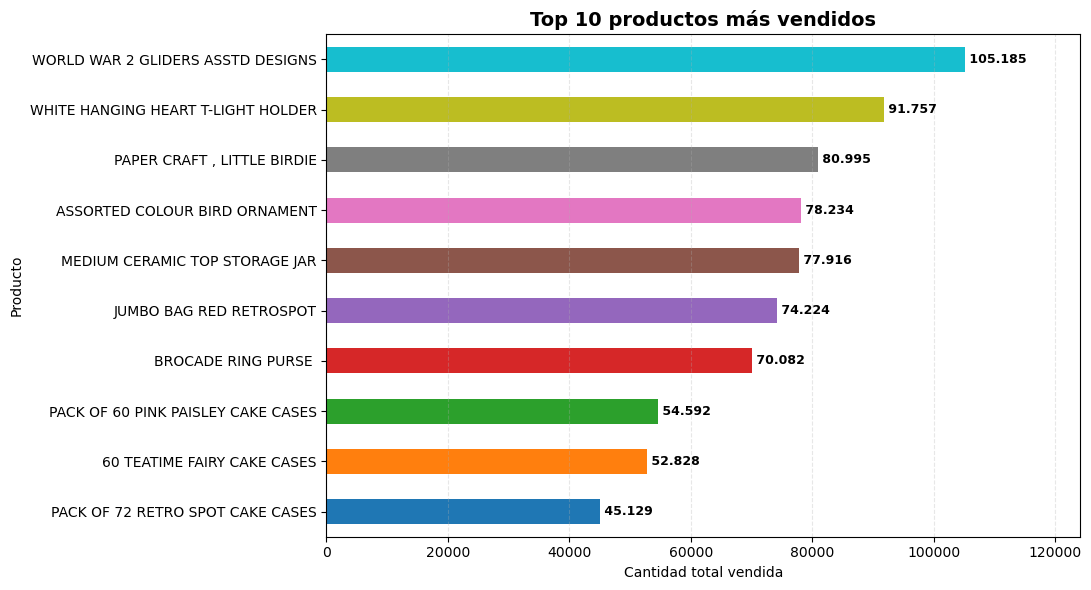

<Figure size 640x480 with 0 Axes>

In [98]:
colores = plt.cm.tab10.colors

datos_grafico = productos_mas_vendidos.sort_values()

ax = datos_grafico.plot(
    kind="barh",
    figsize=(11, 6),
    color=colores
)

plt.title(
    "Top 10 productos más vendidos",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Cantidad total vendida")
plt.ylabel("Producto")

for i, valor in enumerate(datos_grafico):
    etiqueta = f"{valor:,.0f}".replace(",", ".")
    
    ax.text(
        valor,
        i,
        f" {etiqueta}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.xlim(0, datos_grafico.max() * 1.18)
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(
    "productos_mas_vendidos.png",
    dpi=300,
    bbox_inches="tight"
)

### 0.9.7 Productos que generan mayores ingresos

Además de identificar los productos con mayor cantidad de unidades vendidas, se analiza cuáles generan el mayor valor total de ventas.

Este análisis permite diferenciar entre productos de alta rotación y productos con mayor contribución económica.

In [40]:
productos_mayor_ingreso = (
    df_productos
    .groupby("Description")["TotalVenta"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

productos_mayor_ingreso

Description
REGENCY CAKESTAND 3 TIER              277656.25
WHITE HANGING HEART T-LIGHT HOLDER    247048.01
PAPER CRAFT , LITTLE BIRDIE           168469.60
JUMBO BAG RED RETROSPOT               134307.44
ASSORTED COLOUR BIRD ORNAMENT         124351.86
PARTY BUNTING                         103283.38
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
PAPER CHAIN KIT 50'S CHRISTMAS         76598.18
CHILLI LIGHTS                          69084.30
JUMBO BAG STRAWBERRY                   64127.77
Name: TotalVenta, dtype: float64

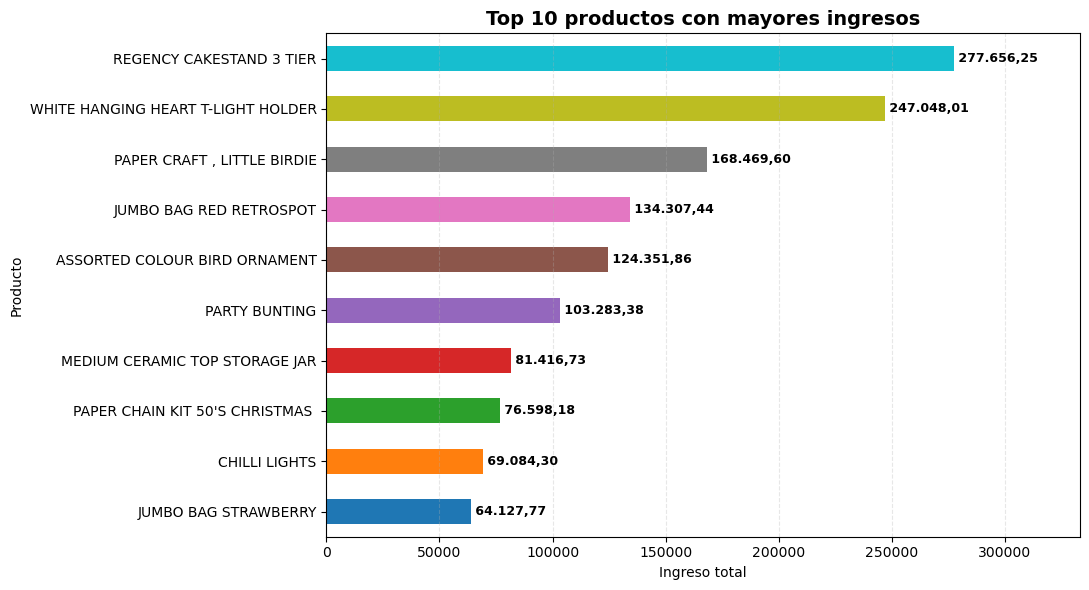

<Figure size 640x480 with 0 Axes>

In [99]:
colores = plt.cm.tab10.colors

datos_ingresos = productos_mayor_ingreso.sort_values()

ax = datos_ingresos.plot(
    kind="barh",
    figsize=(11, 6),
    color=colores
)

plt.title(
    "Top 10 productos con mayores ingresos",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Ingreso total")
plt.ylabel("Producto")

for i, valor in enumerate(datos_ingresos):
    etiqueta = (
        f"{valor:,.2f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

    ax.text(
        valor,
        i,
        f" {etiqueta}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.xlim(0, datos_ingresos.max() * 1.20)
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(
    "productos_mayores_ingresos.png",
    dpi=300,
    bbox_inches="tight"
)

### 0.9.8 Evolución mensual de las ventas

Se analiza la evolución de las ventas a lo largo del tiempo mediante la agrupación mensual de las transacciones.

Este análisis permite identificar tendencias, períodos de crecimiento y posibles comportamientos estacionales.

In [42]:
df_limpio["Mes"] = df_limpio["InvoiceDate"].dt.to_period("M")

In [43]:
ventas_mensuales = (
    df_limpio
    .groupby("Mes")["TotalVenta"]
    .sum()
)

ventas_mensuales

Mes
2009-12     683504.010
2010-01     555802.672
2010-02     504558.956
2010-03     696978.471
2010-04     591982.002
2010-05     597833.380
2010-06     636371.130
2010-07     589736.170
2010-08     602224.600
2010-09     829013.951
2010-10    1033112.010
2010-11    1166460.022
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517208.440
Freq: M, Name: TotalVenta, dtype: float64

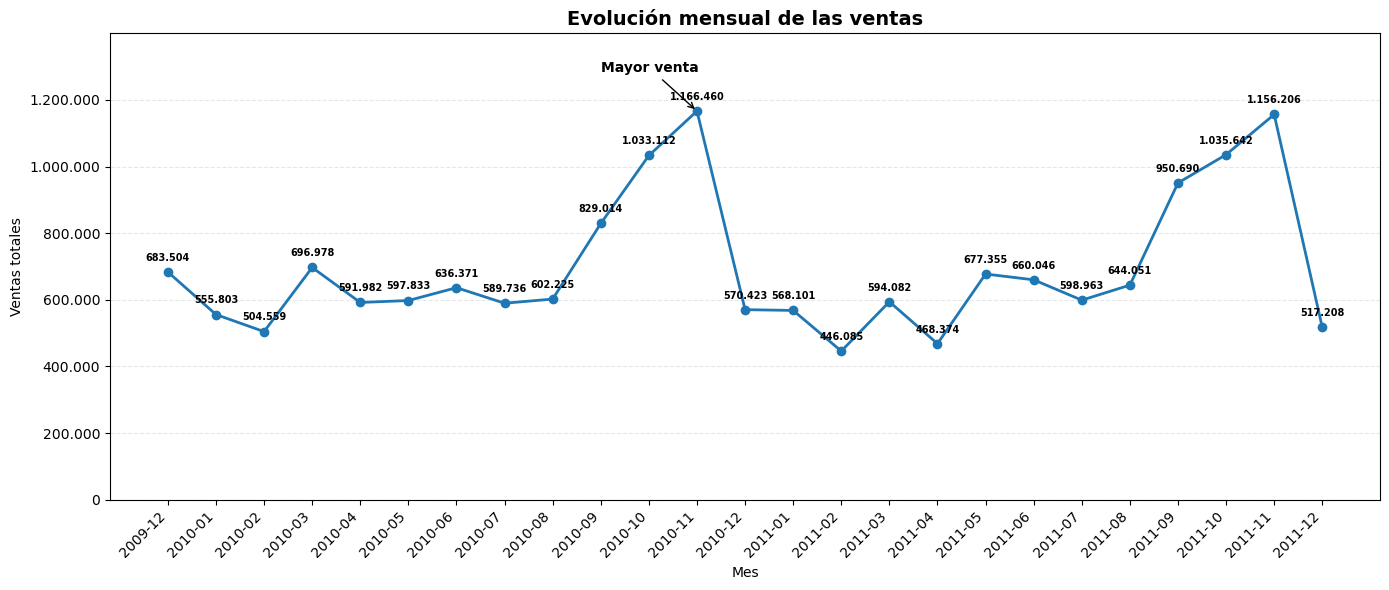

<Figure size 640x480 with 0 Axes>

In [100]:
ventas_plot = ventas_mensuales.copy()

x = range(len(ventas_plot))

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    x,
    ventas_plot.values,
    marker="o",
    linewidth=2
)

# Etiquetas del eje X
ax.set_xticks(list(x))
ax.set_xticklabels(
    [str(mes) for mes in ventas_plot.index],
    rotation=45,
    ha="right"
)

# Títulos
ax.set_title(
    "Evolución mensual de las ventas",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Mes")
ax.set_ylabel("Ventas totales")

# Valores sobre cada punto
for i, valor in enumerate(ventas_plot.values):

    etiqueta = f"{valor:,.0f}".replace(",", ".")

    ax.annotate(
        etiqueta,
        (i, valor),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=7,
        fontweight="bold"
    )

# Mes de mayor venta
pos_max = ventas_plot.values.argmax()
valor_max = ventas_plot.max()

ax.annotate(
    "Mayor venta",
    xy=(pos_max, valor_max),
    xytext=(pos_max - 2, valor_max * 1.10),
    arrowprops=dict(arrowstyle="->"),
    fontsize=10,
    fontweight="bold"
)

# Formato del eje Y
ax.ticklabel_format(style="plain", axis="y")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".")
    )
)

ax.grid(axis="y", linestyle="--", alpha=0.3)

ax.set_ylim(0, ventas_plot.max() * 1.20)

plt.tight_layout()
plt.show()
plt.savefig(
    "ventas_mensuales.png",
    dpi=300,
    bbox_inches="tight"
)

### 0.9.9 Análisis de estacionalidad

Se analiza el comportamiento agregado de las ventas por mes del año con el objetivo de identificar patrones estacionales.

Este análisis permite determinar si ciertos meses presentan niveles de ventas sistemáticamente superiores al resto.

In [45]:
ventas_por_mes = (
    df_limpio
    .assign(MesNumero=df_limpio["InvoiceDate"].dt.month)
    .groupby("MesNumero")["TotalVenta"]
    .sum()
)

ventas_por_mes

MesNumero
1     1123903.982
2      950643.876
3     1291060.231
4     1060356.333
5     1275188.530
6     1296417.180
7     1188699.071
8     1246275.640
9     1779704.153
10    2068754.460
11    2322665.632
12    1771135.180
Name: TotalVenta, dtype: float64

In [46]:
nombres_meses = {
    1: "Enero",
    2: "Febrero",
    3: "Marzo",
    4: "Abril",
    5: "Mayo",
    6: "Junio",
    7: "Julio",
    8: "Agosto",
    9: "Septiembre",
    10: "Octubre",
    11: "Noviembre",
    12: "Diciembre"
}

ventas_estacionales = ventas_por_mes.copy()
ventas_estacionales.index = ventas_estacionales.index.map(nombres_meses)

ventas_estacionales

MesNumero
Enero         1123903.982
Febrero        950643.876
Marzo         1291060.231
Abril         1060356.333
Mayo          1275188.530
Junio         1296417.180
Julio         1188699.071
Agosto        1246275.640
Septiembre    1779704.153
Octubre       2068754.460
Noviembre     2322665.632
Diciembre     1771135.180
Name: TotalVenta, dtype: float64

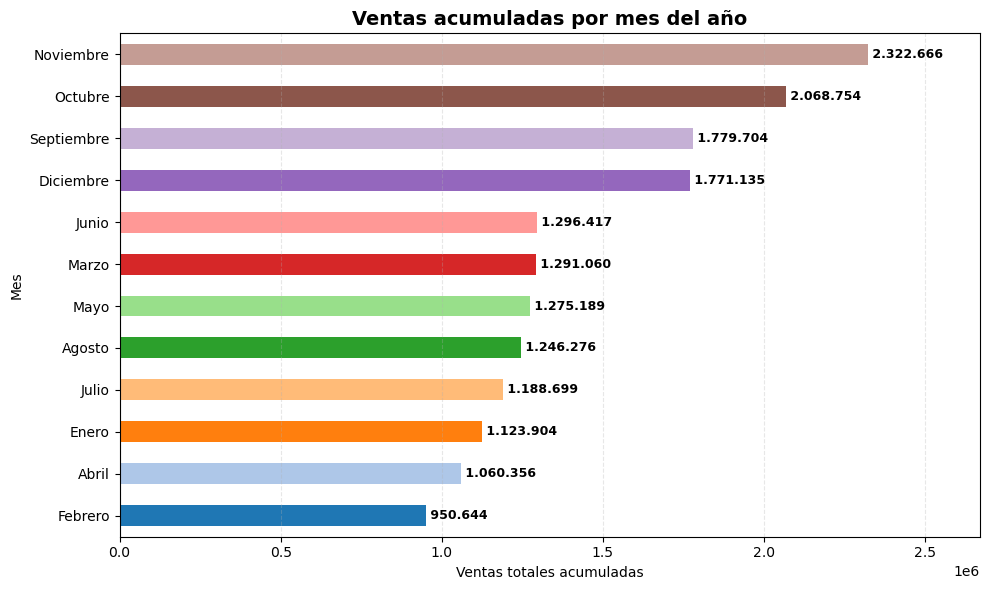

<Figure size 640x480 with 0 Axes>

In [101]:
datos_estacionales = ventas_estacionales.sort_values()

ax = datos_estacionales.plot(
    kind="barh",
    figsize=(10, 6),
    color=plt.cm.tab20.colors
)

plt.title(
    "Ventas acumuladas por mes del año",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Ventas totales acumuladas")
plt.ylabel("Mes")

for i, valor in enumerate(datos_estacionales):
    etiqueta = f"{valor:,.0f}".replace(",", ".")

    ax.text(
        valor,
        i,
        f" {etiqueta}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.xlim(0, datos_estacionales.max() * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(
    "estacionalidad_ventas.png",
    dpi=300,
    bbox_inches="tight"
)

### Interpretación de la estacionalidad

El análisis muestra un comportamiento estacional en las ventas.

Los mayores niveles de ventas se concentran principalmente entre septiembre y noviembre, siendo noviembre el mes con mayor volumen acumulado de ventas, seguido de octubre y septiembre.

Este comportamiento sugiere un incremento de la actividad comercial durante los meses previos a la temporada de fin de año.

Por otro lado, febrero presenta el menor nivel acumulado de ventas dentro del período analizado.

Estos resultados evidencian la existencia de patrones estacionales que podrían ser utilizados posteriormente como variables para la predicción de ventas.

# Parte 1 - Clasificación de clientes

En esta sección se construirá una base resumida por cliente para identificar su comportamiento de compra.

Se utilizarán variables como:

- Frecuencia de compra.
- Cantidad total de productos adquiridos.
- Gasto total realizado.

Posteriormente, se definirán dos categorías de clientes: **Normal** y **Premium**.

## 1.1 Construcción de variables por cliente

Se agrupan las transacciones por `Customer ID` para obtener indicadores de comportamiento de compra por cliente.

In [48]:
clientes = (
    df_limpio
    .groupby("Customer ID")
    .agg(
        Frecuencia=("Invoice", "nunique"),
        CantidadTotal=("Quantity", "sum"),
        GastoTotal=("TotalVenta", "sum")
    )
    .reset_index()
)

clientes.head()

,Customer ID,Frecuencia,CantidadTotal,GastoTotal
0,12346.0,12,74285,77556.46
1,12347.0,8,2967,4921.53
2,12348.0,5,2714,2019.40
3,12349.0,4,1624,4428.69
4,12350.0,1,197,334.40


In [49]:
print("Cantidad total de clientes:", len(clientes))

Cantidad total de clientes: 5878


In [50]:
clientes[
    ["Frecuencia", "CantidadTotal", "GastoTotal"]
].describe()

,Frecuencia,CantidadTotal,GastoTotal
count,5878.000000,5878.000000,5878.000000
mean,6.289384,1788.695475,2955.904095
std,13.009406,8876.297196,14440.852688
min,1.000000,1.000000,2.950000
25%,1.000000,187.000000,342.280000
50%,3.000000,480.000000,867.740000
75%,7.000000,1350.000000,2248.305000
max,398.000000,367193.000000,580987.040000


## 1.2 Definición de Cliente Normal y Cliente Premium

Para clasificar a los clientes se utiliza el nivel de gasto total realizado durante el período analizado.

Se define como **Cliente Premium** a aquel cuyo gasto total se encuentra en el 25% superior de la distribución de clientes.

Los demás clientes se clasifican como **Clientes Normales**.

In [51]:
umbral_premium = clientes["GastoTotal"].quantile(0.75)

print("Umbral para Cliente Premium:", umbral_premium)

Umbral para Cliente Premium: 2248.305


In [52]:
clientes["TipoCliente"] = np.where(
    clientes["GastoTotal"] >= umbral_premium,
    "Premium",
    "Normal"
)

clientes.head()

,Customer ID,Frecuencia,CantidadTotal,GastoTotal,TipoCliente
0,12346.0,12,74285,77556.46,Premium
1,12347.0,8,2967,4921.53,Premium
2,12348.0,5,2714,2019.40,Normal
3,12349.0,4,1624,4428.69,Premium
4,12350.0,1,197,334.40,Normal


In [53]:
clientes["TipoCliente"].value_counts()

TipoCliente
Normal     4408
Premium    1470
Name: count, dtype: int64

In [54]:
clientes["TipoCliente"].value_counts(normalize=True) * 100

TipoCliente
Normal     74.991494
Premium    25.008506
Name: proportion, dtype: float64

## 1.3 Preparación de variables para el modelo de clasificación

Se seleccionan como variables predictoras la frecuencia de compra y la cantidad total adquirida.

La variable objetivo será `TipoCliente`, que clasifica a los clientes como **Normal** o **Premium**.

In [55]:
X = clientes[["Frecuencia", "CantidadTotal"]]
y = clientes["TipoCliente"]

print("Variables predictoras:")
print(X.head())

print("\nVariable objetivo:")
print(y.head())

Variables predictoras:
   Frecuencia  CantidadTotal
0          12          74285
1           8           2967
2           5           2714
3           4           1624
4           1            197

Variable objetivo:
0    Premium
1    Premium
2     Normal
3    Premium
4     Normal
Name: TipoCliente, dtype: object


## 1.4 División del conjunto de datos

Los datos se dividen en un conjunto de entrenamiento y un conjunto de prueba.

El conjunto de entrenamiento se utiliza para ajustar el modelo, mientras que el conjunto de prueba permite evaluar su capacidad de clasificación sobre datos no utilizados durante el entrenamiento.

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (4702, 2)
Datos de prueba: (1176, 2)


## 1.5 Entrenamiento del modelo de clasificación

Se utiliza un modelo de **Random Forest** para clasificar a los clientes en las categorías Normal y Premium.

Este algoritmo combina múltiples árboles de decisión y permite capturar relaciones no lineales entre las variables predictoras.

In [57]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

modelo_rf.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente")

Modelo Random Forest entrenado correctamente


In [58]:
y_pred = modelo_rf.predict(X_test)

print("Predicciones realizadas correctamente")

Predicciones realizadas correctamente


## 1.6 Evaluación del modelo

El rendimiento del modelo se evalúa mediante métricas de clasificación como exactitud, precisión, recall y F1-score.

In [59]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy del modelo: {accuracy:.4f}")
print()
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred))

Accuracy del modelo: 0.9192

Reporte de clasificación:
              precision    recall  f1-score   support

      Normal       0.95      0.94      0.95       882
     Premium       0.84      0.84      0.84       294

    accuracy                           0.92      1176
   macro avg       0.89      0.89      0.89      1176
weighted avg       0.92      0.92      0.92      1176



## 1.7 Matriz de confusión

Se utiliza una matriz de confusión para observar cuántos clientes fueron clasificados correctamente y cuántos fueron asignados a una categoría incorrecta.

Esta herramienta permite complementar la evaluación del modelo y entender mejor los errores de clasificación.

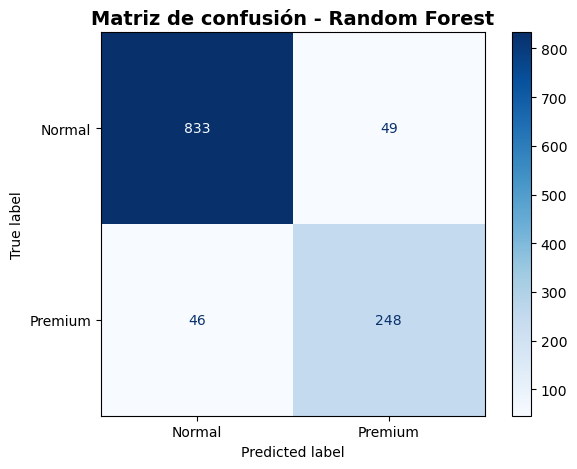

In [107]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Variables de clasificación
X_clas = clientes[["Frecuencia", "CantidadTotal"]]
y_clas = clientes["TipoCliente"]

# Volver a realizar la división
X_train_clas, X_test_clas, y_train_clas, y_test_clas = train_test_split(
    X_clas,
    y_clas,
    test_size=0.20,
    random_state=42,
    stratify=y_clas
)

# Generar nuevamente las predicciones con el modelo de clasificación
y_pred_clas = modelo_rf.predict(X_test_clas)

# Matriz de confusión
cm = confusion_matrix(
    y_test_clas,
    y_pred_clas,
    labels=["Normal", "Premium"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Premium"]
)

disp.plot(cmap="Blues")

plt.title(
    "Matriz de confusión - Random Forest",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "matriz_confusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación del modelo de clasificación

El modelo Random Forest alcanzó una exactitud aproximada del **91,92%**, lo que indica un buen desempeño general en la clasificación de clientes.

La categoría Normal presenta mejores métricas de precisión y recall, mientras que la categoría Premium presenta valores cercanos al 84%.

Esto indica que el modelo logra identificar adecuadamente a la mayoría de clientes Premium, aunque existe un mayor nivel de error en esta categoría en comparación con los clientes Normales.

# Parte 2 - Segmentación de clientes

En esta sección se aplicarán técnicas de aprendizaje no supervisado para identificar grupos de clientes con comportamientos similares.

Se utilizarán los algoritmos:

- K-Means.
- Mean Shift.

Posteriormente, se analizarán las características de cada segmento y se compararán los resultados obtenidos.

## 2.1 Preparación de variables para segmentación

Para realizar el agrupamiento se utilizan variables relacionadas con el comportamiento de compra de cada cliente:

- Frecuencia de compra.
- Cantidad total adquirida.
- Gasto total realizado.

In [61]:
X_cluster = clientes[
    ["Frecuencia", "CantidadTotal", "GastoTotal"]
].copy()

X_cluster.head()

,Frecuencia,CantidadTotal,GastoTotal
0,12,74285,77556.46
1,8,2967,4921.53
2,5,2714,2019.40
3,4,1624,4428.69
4,1,197,334.40


## 2.2 Estandarización de las variables

Antes de aplicar los algoritmos de agrupamiento, las variables son estandarizadas para evitar que aquellas con valores numéricos más altos tengan mayor influencia sobre la formación de los grupos.

In [62]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_cluster_scaled = scaler.fit_transform(X_cluster)

print("Variables estandarizadas correctamente")
print("Dimensiones:", X_cluster_scaled.shape)

Variables estandarizadas correctamente
Dimensiones: (5878, 3)


## 2.3 Determinación del número de clusters

Antes de aplicar K-Means, se utiliza el método del codo para identificar un número adecuado de grupos.

Este método evalúa cómo disminuye la inercia a medida que aumenta el número de clusters.

In [63]:
from sklearn.cluster import KMeans

inercias = []

rango_k = range(1, 11)

for k in rango_k:
    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    modelo_kmeans.fit(X_cluster_scaled)
    inercias.append(modelo_kmeans.inertia_)

print("Cálculo de inercias completado")

Cálculo de inercias completado


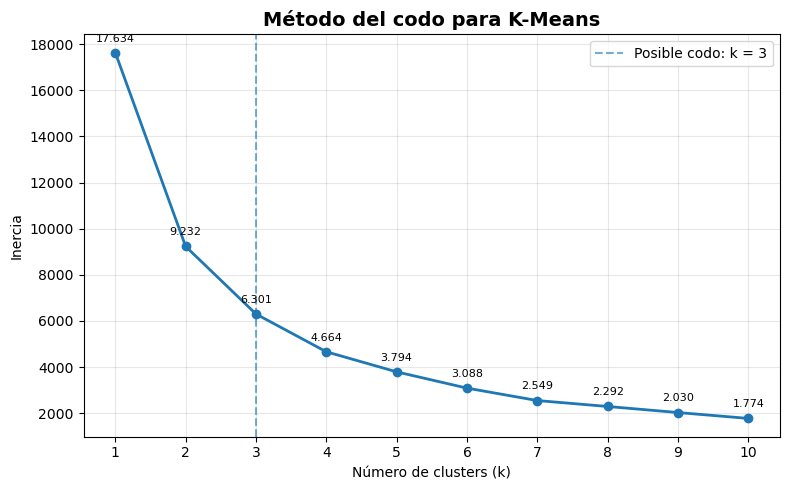

<Figure size 640x480 with 0 Axes>

In [103]:
plt.figure(figsize=(8, 5))

plt.plot(
    rango_k,
    inercias,
    marker="o",
    linewidth=2
)

plt.title(
    "Método del codo para K-Means",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")

plt.xticks(rango_k)

# Agregar etiquetas con el valor de la inercia
for k, inercia in zip(rango_k, inercias):
    plt.annotate(
        f"{inercia:,.0f}".replace(",", "."),
        (k, inercia),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

# Resaltar posible punto de codo
plt.axvline(
    x=3,
    linestyle="--",
    alpha=0.6,
    label="Posible codo: k = 3"
)

plt.legend()

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
plt.savefig(
    "metodo_codo_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)

## 2.4 Aplicación del algoritmo K-Means

A partir del método del codo se seleccionan **3 clusters** como una solución adecuada para segmentar a los clientes.

El modelo K-Means agrupará a los clientes según su frecuencia de compra, cantidad total adquirida y gasto total.

In [66]:
modelo_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clientes["Cluster_KMeans"] = modelo_kmeans.fit_predict(X_cluster_scaled)

clientes.head()

,Customer ID,Frecuencia,CantidadTotal,GastoTotal,TipoCliente,Cluster_KMeans
0,12346.0,12,74285,77556.46,Premium,2
1,12347.0,8,2967,4921.53,Premium,0
2,12348.0,5,2714,2019.40,Normal,0
3,12349.0,4,1624,4428.69,Premium,0
4,12350.0,1,197,334.40,Normal,0


In [67]:
clientes["Cluster_KMeans"].value_counts().sort_index()

Cluster_KMeans
0    5830
1       5
2      43
Name: count, dtype: int64

In [68]:
perfil_kmeans = (
    clientes
    .groupby("Cluster_KMeans")[
        ["Frecuencia", "CantidadTotal", "GastoTotal"]
    ]
    .mean()
    .round(2)
)

perfil_kmeans

,Frecuencia,CantidadTotal,GastoTotal
Cluster_KMeans,,,
0,5.56,1222.88,2116.20
1,198.60,209867.20,382017.74
2,82.49,54307.00,72726.97


## 2.5 Interpretación de los clusters obtenidos con K-Means

El algoritmo K-Means identificó tres grupos de clientes con características diferenciadas.

- **Cluster 0:** concentra la gran mayoría de los clientes y presenta niveles relativamente bajos de frecuencia, cantidad adquirida y gasto total.
- **Cluster 1:** está compuesto por un número muy reducido de clientes con niveles extremadamente altos de frecuencia, cantidad comprada y gasto total.
- **Cluster 2:** agrupa clientes de alto valor, con niveles de compra y gasto considerablemente superiores al grupo principal, aunque inferiores al Cluster 1.

Los resultados muestran una segmentación fuertemente influenciada por clientes con comportamientos de compra muy elevados.

## 2.6 Evaluación de la segmentación K-Means

Se utiliza el coeficiente de silueta (Silhouette Score) para evaluar qué tan bien separados se encuentran los clusters.

Este indicador toma valores entre -1 y 1. Valores más cercanos a 1 representan una mejor separación entre los grupos.

In [70]:
from sklearn.metrics import silhouette_score

silhouette_kmeans = silhouette_score(
    X_cluster_scaled,
    clientes["Cluster_KMeans"]
)

print(f"Silhouette Score de K-Means: {silhouette_kmeans:.4f}")

Silhouette Score de K-Means: 0.9398


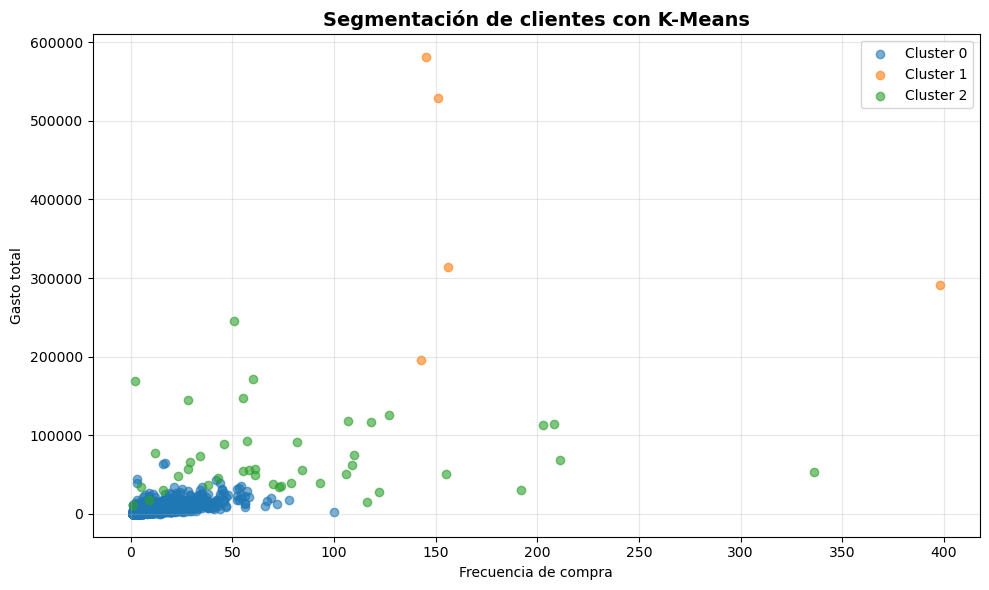

<Figure size 640x480 with 0 Axes>

In [104]:
plt.figure(figsize=(10, 6))

for cluster in sorted(clientes["Cluster_KMeans"].unique()):
    
    datos = clientes[
        clientes["Cluster_KMeans"] == cluster
    ]
    
    plt.scatter(
        datos["Frecuencia"],
        datos["GastoTotal"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.title(
    "Segmentación de clientes con K-Means",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Frecuencia de compra")
plt.ylabel("Gasto total")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(
    "segmentacion_kmeans.png",
    dpi=300,
    bbox_inches="tight"
)

In [72]:
from sklearn.metrics import silhouette_score

silhouette_kmeans = silhouette_score(
    X_cluster_scaled,
    clientes["Cluster_KMeans"]
)

print(f"Silhouette Score de K-Means: {silhouette_kmeans:.4f}")

Silhouette Score de K-Means: 0.9398


### Visualización complementaria de K-Means

Debido a la presencia de clientes con niveles de gasto y frecuencia muy elevados, se utiliza una escala logarítmica para visualizar con mayor claridad la distribución de los segmentos.

Esta transformación se utiliza únicamente con fines gráficos y no modifica el modelo K-Means previamente entrenado.

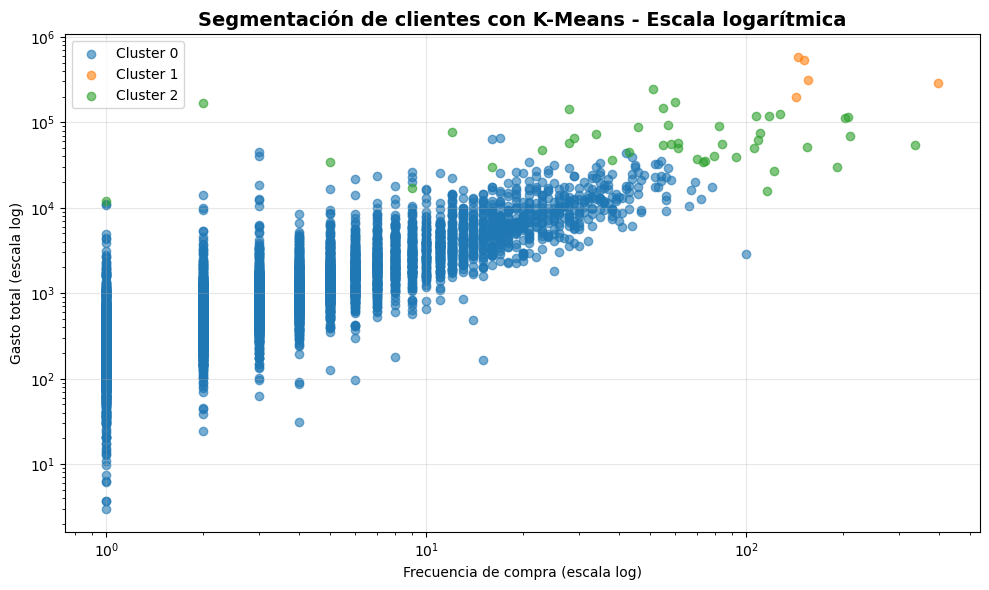

<Figure size 640x480 with 0 Axes>

In [105]:
plt.figure(figsize=(10, 6))

for cluster in sorted(clientes["Cluster_KMeans"].unique()):

    datos = clientes[
        clientes["Cluster_KMeans"] == cluster
    ]

    plt.scatter(
        datos["Frecuencia"],
        datos["GastoTotal"],
        label=f"Cluster {cluster}",
        alpha=0.6
    )

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Segmentación de clientes con K-Means - Escala logarítmica",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Frecuencia de compra (escala log)")
plt.ylabel("Gasto total (escala log)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(
    "segmentacion_kmeans_log.png",
    dpi=300,
    bbox_inches="tight"
)

### Interpretación de la visualización K-Means

La escala logarítmica permite observar con mayor claridad la distribución de los clientes.

El **Cluster 0** concentra la mayor parte de los clientes, con niveles bajos y medios de frecuencia y gasto.

El **Cluster 2** agrupa clientes con mayor frecuencia de compra y mayor gasto total, mientras que el **Cluster 1** contiene un número muy reducido de clientes con valores excepcionalmente altos.

Esto confirma que existen clientes con comportamientos de compra muy superiores al promedio, los cuales influyen de manera importante en la formación de los clusters.

## 2.7 Segmentación de clientes con Mean Shift

Se aplica el algoritmo **Mean Shift** para identificar grupos de clientes sin definir previamente el número de clusters.

A diferencia de K-Means, Mean Shift determina automáticamente la cantidad de grupos a partir de la distribución de los datos.

In [74]:
from sklearn.cluster import MeanShift, estimate_bandwidth

bandwidth = estimate_bandwidth(
    X_cluster_scaled,
    quantile=0.2,
    n_samples=1000
)

print("Bandwidth estimado:", bandwidth)

Bandwidth estimado: 0.36252546905253746


In [75]:
modelo_meanshift = MeanShift(
    bandwidth=bandwidth,
    bin_seeding=True
)

clientes["Cluster_MeanShift"] = modelo_meanshift.fit_predict(
    X_cluster_scaled
)

print(
    "Número de clusters encontrados:",
    clientes["Cluster_MeanShift"].nunique()
)

Número de clusters encontrados: 95


In [76]:
clientes["Cluster_MeanShift"].value_counts().sort_index()

Cluster_MeanShift
0     5204
1      295
2       46
3       61
4       18
      ... 
91       1
92       1
93       1
94       1
95       1
Name: count, Length: 95, dtype: int64

## 2.8 Ajuste del parámetro bandwidth en Mean Shift

El primer modelo Mean Shift identificó una cantidad elevada de clusters, lo que dificulta su interpretación comercial.

Por esta razón, se prueban diferentes valores del parámetro `quantile` para obtener un ancho de banda mayor y reducir la fragmentación de los grupos.

In [77]:
from sklearn.cluster import MeanShift, estimate_bandwidth

quantiles = [0.20, 0.25, 0.30, 0.35, 0.40]

for q in quantiles:
    
    bandwidth_q = estimate_bandwidth(
        X_cluster_scaled,
        quantile=q,
        n_samples=1000
    )
    
    modelo_q = MeanShift(
        bandwidth=bandwidth_q,
        bin_seeding=True
    )
    
    etiquetas_q = modelo_q.fit_predict(X_cluster_scaled)
    
    numero_clusters = len(np.unique(etiquetas_q))
    
    print(
        f"Quantile: {q:.2f} | "
        f"Bandwidth: {bandwidth_q:.4f} | "
        f"Clusters: {numero_clusters}"
    )

Quantile: 0.20 | Bandwidth: 0.3625 | Clusters: 95
Quantile: 0.25 | Bandwidth: 0.3901 | Clusters: 90
Quantile: 0.30 | Bandwidth: 0.4195 | Clusters: 85
Quantile: 0.35 | Bandwidth: 0.4413 | Clusters: 81
Quantile: 0.40 | Bandwidth: 0.4608 | Clusters: 81


## 2.9 Modelo definitivo de Mean Shift

Después de probar diferentes valores del parámetro `quantile`, se selecciona un valor de **0,40**.

Este valor genera un ancho de banda mayor y reduce la fragmentación observada en el modelo inicial.

A diferencia de K-Means, Mean Shift determina automáticamente el número de clusters a partir de la densidad de los datos.

In [78]:
bandwidth_final = estimate_bandwidth(
    X_cluster_scaled,
    quantile=0.40,
    n_samples=1000
)

modelo_meanshift_final = MeanShift(
    bandwidth=bandwidth_final,
    bin_seeding=True
)

clientes["Cluster_MeanShift"] = modelo_meanshift_final.fit_predict(
    X_cluster_scaled
)

print("Bandwidth final:", bandwidth_final)
print(
    "Número de clusters encontrados:",
    clientes["Cluster_MeanShift"].nunique()
)

Bandwidth final: 0.46077206754430744
Número de clusters encontrados: 81


In [79]:
conteo_meanshift = (
    clientes["Cluster_MeanShift"]
    .value_counts()
    .sort_values(ascending=False)
)

conteo_meanshift.head(15)

Cluster_MeanShift
0     5366
3      214
1      109
6       31
2       23
11      15
20      12
7        7
5        6
4        6
12       4
9        4
8        3
19       3
10       3
Name: count, dtype: int64

In [80]:
clusters_principales = conteo_meanshift.head(5).index

perfil_meanshift = (
    clientes[
        clientes["Cluster_MeanShift"].isin(clusters_principales)
    ]
    .groupby("Cluster_MeanShift")[
        ["Frecuencia", "CantidadTotal", "GastoTotal"]
    ]
    .mean()
    .round(2)
)

perfil_meanshift

,Frecuencia,CantidadTotal,GastoTotal
Cluster_MeanShift,,,
0,4.00,737.85,1267.57
1,32.30,5059.91,9727.54
2,30.00,9159.17,17081.49
3,15.60,4812.52,8770.98
6,22.52,8907.84,15864.50


## 2.10 Interpretación de los clusters Mean Shift

Mean Shift genera una segmentación más detallada que K-Means, identificando numerosos grupos según la densidad de los datos.

Al analizar los cinco clusters principales se observan diferentes niveles de comportamiento:

- **Cluster 0:** clientes de menor frecuencia, cantidad comprada y gasto total.
- **Cluster 3:** clientes con comportamiento intermedio.
- **Cluster 1:** clientes frecuentes con un nivel de gasto superior al promedio.
- **Cluster 6:** clientes con cantidades adquiridas y gasto elevados.
- **Cluster 2:** clientes con altos niveles de cantidad comprada y gasto total.

La segmentación obtenida muestra que Mean Shift identifica grupos más específicos, aunque genera una mayor cantidad de clusters y, por tanto, una interpretación comercial más compleja.

## 2.11 Evaluación de Mean Shift

Se utiliza el Silhouette Score para evaluar la separación de los grupos obtenidos mediante Mean Shift y posteriormente compararlo con K-Means.

In [81]:
silhouette_meanshift = silhouette_score(
    X_cluster_scaled,
    clientes["Cluster_MeanShift"]
)

print(f"Silhouette Score de Mean Shift: {silhouette_meanshift:.4f}")

Silhouette Score de Mean Shift: 0.6418


## 2.12 Comparación entre K-Means y Mean Shift

Se comparan los resultados obtenidos mediante ambos algoritmos considerando el número de clusters identificados y el Silhouette Score.

In [82]:
comparacion_clustering = pd.DataFrame({
    "Algoritmo": ["K-Means", "Mean Shift"],
    "Número de clusters": [
        clientes["Cluster_KMeans"].nunique(),
        clientes["Cluster_MeanShift"].nunique()
    ],
    "Silhouette Score": [
        silhouette_kmeans,
        silhouette_meanshift
    ]
})

comparacion_clustering

,Algoritmo,Número de clusters,Silhouette Score
0,K-Means,3,0.939765
1,Mean Shift,81,0.641793


## 2.13 Conclusión de la segmentación

Los resultados muestran diferencias importantes entre los dos algoritmos de agrupamiento.

**K-Means** identificó 3 clusters y obtuvo un Silhouette Score de **0,9398**, lo que indica una separación muy clara entre los grupos formados.

Por su parte, **Mean Shift** identificó 81 clusters y alcanzó un Silhouette Score de **0,6418**. Aunque este valor indica una segmentación aceptable, la gran cantidad de grupos generados dificulta su interpretación comercial.

En este caso, **K-Means presenta un mejor desempeño**, ya que combina una mayor separación entre los clusters con una estructura mucho más sencilla de interpretar.

Por esta razón, K-Means se considera el método más adecuado para la segmentación de clientes dentro de este conjunto de datos.

# Parte 3 - Predicción de ventas

En esta sección se desarrollará un modelo de aprendizaje automático para predecir las ventas futuras a partir del comportamiento histórico de las transacciones.

Para ello se crearán variables temporales, se dividirán los datos en conjuntos de entrenamiento y prueba, se entrenará un modelo de regresión y se evaluará su desempeño.

## 3.1 Preparación de los datos para predicción

Se agrupan las ventas por mes para construir una serie histórica que permita modelar la evolución de las ventas en el tiempo.

In [83]:
ventas_prediccion = (
    df_limpio
    .set_index("InvoiceDate")
    .resample("ME")["TotalVenta"]
    .sum()
    .reset_index()
)

ventas_prediccion.head()

,InvoiceDate,TotalVenta
0,2009-12-31,683504.010
1,2010-01-31,555802.672
2,2010-02-28,504558.956
3,2010-03-31,696978.471
4,2010-04-30,591982.002


In [84]:
print("Cantidad de meses:", len(ventas_prediccion))

Cantidad de meses: 25


## 3.2 Creación de variables predictoras

Para mejorar la capacidad predictiva del modelo se crean variables temporales a partir de la fecha de cada período.

Se incorporan:

- Año.
- Mes.
- Tendencia temporal.
- Venta del mes anterior.

In [85]:
ventas_prediccion["Año"] = ventas_prediccion["InvoiceDate"].dt.year
ventas_prediccion["Mes"] = ventas_prediccion["InvoiceDate"].dt.month

ventas_prediccion["Tendencia"] = range(1, len(ventas_prediccion) + 1)

ventas_prediccion["VentaAnterior"] = ventas_prediccion["TotalVenta"].shift(1)

ventas_prediccion.head()

,InvoiceDate,TotalVenta,Año,Mes,Tendencia,VentaAnterior
0,2009-12-31,683504.010,2009,12,1,NaN
1,2010-01-31,555802.672,2010,1,2,683504.010
2,2010-02-28,504558.956,2010,2,3,555802.672
3,2010-03-31,696978.471,2010,3,4,504558.956
4,2010-04-30,591982.002,2010,4,5,696978.471


In [86]:
ventas_modelo = ventas_prediccion.dropna().copy()

print("Registros disponibles para el modelo:", len(ventas_modelo))

ventas_modelo.head()

Registros disponibles para el modelo: 24


,InvoiceDate,TotalVenta,Año,Mes,Tendencia,VentaAnterior
1,2010-01-31,555802.672,2010,1,2,683504.010
2,2010-02-28,504558.956,2010,2,3,555802.672
3,2010-03-31,696978.471,2010,3,4,504558.956
4,2010-04-30,591982.002,2010,4,5,696978.471
5,2010-05-31,597833.380,2010,5,6,591982.002


## 3.3 División temporal entre entrenamiento y prueba

Debido a que los datos corresponden a una serie temporal, la división entre entrenamiento y prueba se realiza respetando el orden cronológico.

Los primeros períodos se utilizan para entrenar el modelo y los últimos meses se reservan para evaluar su capacidad predictiva.

In [87]:
X = ventas_modelo[
    ["Año", "Mes", "Tendencia", "VentaAnterior"]
]

y = ventas_modelo["TotalVenta"]

In [88]:
X_train = X.iloc[:-5]
X_test = X.iloc[-5:]

y_train = y.iloc[:-5]
y_test = y.iloc[-5:]

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

Registros de entrenamiento: 19
Registros de prueba: 5


In [89]:
ventas_modelo.iloc[-5:][
    ["InvoiceDate", "TotalVenta"]
]

,InvoiceDate,TotalVenta
20,2011-08-31,644051.040
21,2011-09-30,950690.202
22,2011-10-31,1035642.450
23,2011-11-30,1156205.610
24,2011-12-31,517208.440


## 3.4 Entrenamiento del modelo de predicción

Se utiliza un modelo **Random Forest Regressor** para predecir el valor mensual de las ventas.

Este algoritmo permite capturar relaciones no lineales entre las variables temporales y el comportamiento histórico de las ventas.

In [90]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf_reg = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

modelo_rf_reg.fit(X_train, y_train)

print("Modelo Random Forest Regressor entrenado correctamente")

Modelo Random Forest Regressor entrenado correctamente


In [91]:
y_pred = modelo_rf_reg.predict(X_test)

print("Predicciones realizadas correctamente")

Predicciones realizadas correctamente


## 3.5 Comparación entre valores reales y predichos

Se comparan las ventas reales del conjunto de prueba con las ventas estimadas por el modelo.

In [93]:
resultados_prediccion = ventas_modelo.iloc[-5:][
    ["InvoiceDate", "TotalVenta"]
].copy()

resultados_prediccion["VentaPredicha"] = y_pred

resultados_prediccion

,InvoiceDate,TotalVenta,VentaPredicha
20,2011-08-31,644051.040,603569.905220
21,2011-09-30,950690.202,763449.751000
22,2011-10-31,1035642.450,976405.627650
23,2011-11-30,1156205.610,975150.989165
24,2011-12-31,517208.440,760931.077885


## 3.6 Evaluación del modelo de predicción

El desempeño del modelo se evalúa mediante tres métricas:

- **MAE (Mean Absolute Error):** mide el error promedio absoluto entre las ventas reales y las predichas.
- **RMSE (Root Mean Squared Error):** penaliza con mayor fuerza los errores grandes.
- **R²:** indica qué proporción de la variabilidad de las ventas es explicada por el modelo.

In [94]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²: {r2:.4f}")

MAE: 142,347.13
RMSE: 162,719.52
R²: 0.5450


### Evaluación complementaria sin diciembre de 2011

Debido a que diciembre de 2011 contiene información únicamente hasta el día 9, se realiza una evaluación adicional excluyendo este período para evitar que un mes incompleto distorsione las métricas del modelo.

In [95]:
y_test_completo = y_test.iloc[:-1]
y_pred_completo = y_pred[:-1]

mae_completo = mean_absolute_error(y_test_completo, y_pred_completo)
rmse_completo = np.sqrt(
    mean_squared_error(y_test_completo, y_pred_completo)
)
r2_completo = r2_score(y_test_completo, y_pred_completo)

print(f"MAE sin diciembre 2011: {mae_completo:,.2f}")
print(f"RMSE sin diciembre 2011: {rmse_completo:,.2f}")
print(f"R² sin diciembre 2011: {r2_completo:.4f}")

MAE sin diciembre 2011: 117,003.26
RMSE sin diciembre 2011: 135,080.98
R² sin diciembre 2011: 0.4911


### Interpretación de la evaluación

El modelo Random Forest Regressor presenta una capacidad predictiva moderada.

Considerando todos los meses del conjunto de prueba, se obtiene un R² de 0,5450, lo que indica que el modelo explica aproximadamente el 54,5% de la variabilidad observada en las ventas.

El MAE fue de 142.347,13 y el RMSE de 162.719,52, lo que evidencia que todavía existen diferencias relevantes entre los valores reales y las predicciones.

Al excluir diciembre de 2011, mes que contiene información únicamente hasta el día 9, el MAE disminuye a 117.003,26 y el RMSE a 135.080,98.

Esto indica que el mes incompleto afecta el nivel de error del modelo. Sin embargo, el R² debe interpretarse con cautela debido al reducido número de períodos disponibles para evaluación.

## 3.7 Visualización de ventas reales y predichas

Se comparan gráficamente las ventas reales con las estimadas por el modelo para observar la capacidad de seguimiento de la tendencia temporal.

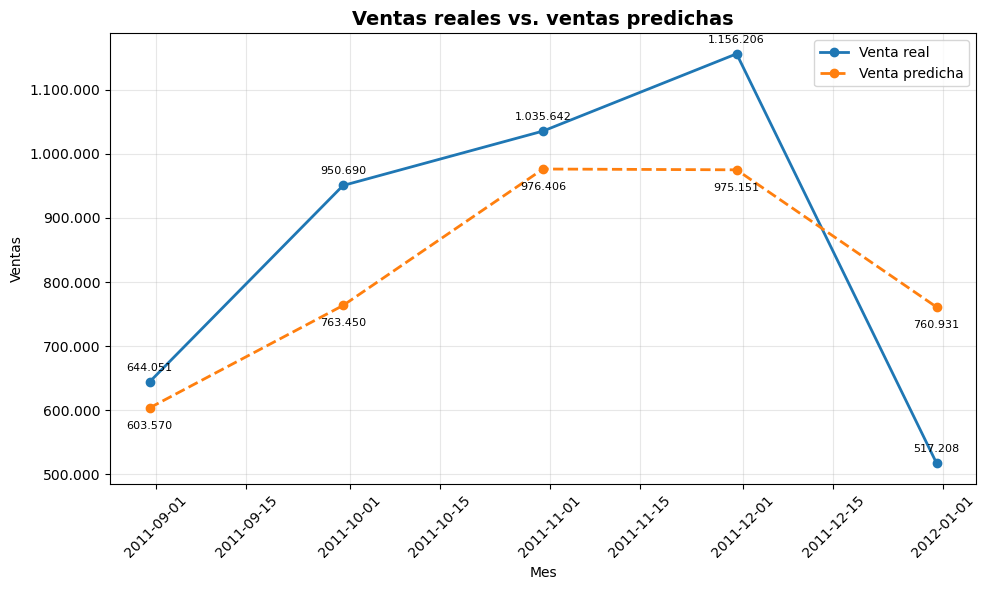

<Figure size 640x480 with 0 Axes>

In [106]:
fig, ax = plt.subplots(figsize=(10, 6))

fechas_prueba = resultados_prediccion["InvoiceDate"]

ax.plot(
    fechas_prueba,
    resultados_prediccion["TotalVenta"],
    marker="o",
    linewidth=2,
    label="Venta real"
)

ax.plot(
    fechas_prueba,
    resultados_prediccion["VentaPredicha"],
    marker="o",
    linewidth=2,
    linestyle="--",
    label="Venta predicha"
)

# Etiquetas de valores
for fecha, real, pred in zip(
    fechas_prueba,
    resultados_prediccion["TotalVenta"],
    resultados_prediccion["VentaPredicha"]
):
    ax.annotate(
        f"{real:,.0f}".replace(",", "."),
        (fecha, real),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

    ax.annotate(
        f"{pred:,.0f}".replace(",", "."),
        (fecha, pred),
        textcoords="offset points",
        xytext=(0, -15),
        ha="center",
        fontsize=8
    )

ax.set_title(
    "Ventas reales vs. ventas predichas",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Mes")
ax.set_ylabel("Ventas")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, pos: f"{x:,.0f}".replace(",", ".")
    )
)

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()
plt.savefig(
    "ventas_reales_predichas.png",
    dpi=300,
    bbox_inches="tight"
)

## 3.8 Conclusión de la predicción de ventas

El modelo Random Forest Regressor logró capturar parcialmente la tendencia de las ventas mensuales.

Las predicciones muestran un comportamiento similar al observado en los valores reales, especialmente en los meses de agosto, octubre y noviembre, aunque existen diferencias importantes en algunos períodos.

El modelo obtuvo un R² de 0,5450, lo que indica una capacidad predictiva moderada. El MAE fue de 142.347,13 y el RMSE de 162.719,52.

Al excluir diciembre de 2011, mes que contiene información únicamente hasta el día 9, los errores disminuyen, evidenciando que este período incompleto afecta la evaluación del modelo.

En conclusión, el modelo permite aproximar la evolución general de las ventas, aunque su desempeño podría mejorar incorporando más períodos históricos, nuevas variables explicativas y técnicas adicionales de modelado.

# Conclusiones generales

El desarrollo del taller permitió aplicar diferentes técnicas de aprendizaje automático al conjunto de datos **Online Retail II**, integrando procesos de preparación, análisis exploratorio, clasificación, segmentación y predicción de ventas.

En la etapa de preparación se realizó la limpieza del conjunto de datos, eliminando registros duplicados, pedidos cancelados, transacciones sin identificación del cliente y registros con precios iguales a cero. Posteriormente, el análisis exploratorio permitió identificar los productos más vendidos, los productos con mayores ingresos y los principales patrones temporales de las ventas.

Para la clasificación de clientes se definieron las categorías **Normal** y **Premium** utilizando el gasto total como criterio. El modelo Random Forest alcanzó una exactitud aproximada del **91,92%**, mostrando un buen desempeño general.

En la segmentación de clientes, K-Means obtuvo mejores resultados que Mean Shift. K-Means identificó 3 grupos con un Silhouette Score de **0,9398**, mientras que Mean Shift generó 81 clusters con un Silhouette Score de **0,6418**. Esto indica que K-Means proporciona una segmentación más clara y fácil de interpretar comercialmente.

Finalmente, se desarrolló un modelo Random Forest Regressor para la predicción de ventas mensuales. El modelo obtuvo un R² de **0,5450**, mostrando una capacidad predictiva moderada. Los resultados evidencian que el comportamiento histórico y las variables temporales permiten aproximar la tendencia general de las ventas, aunque el modelo podría mejorar con una mayor cantidad de períodos históricos y variables adicionales.

En conjunto, el taller demuestra cómo las técnicas de aprendizaje automático pueden utilizarse para transformar datos transaccionales en información útil para conocer a los clientes, identificar segmentos de comportamiento y apoyar la planificación comercial.